Name: Hasnain khan

Roll No: 23102A0075

R-Programming Lab 1

In [ ]:
help.search("data input")

In [ ]:
help

function (topic, package = NULL, lib.loc = NULL, verbose = getOption("verbose"), 
    try.all.packages = getOption("help.try.all.packages"), help_type = getOption("help_type")) 
{
    types <- c("text", "html", "pdf")
    help_type <- if (!length(help_type)) 
        "text"
    else match.arg(tolower(help_type), types)
    if (!missing(package)) 
        if (is.name(y <- substitute(package))) 
            package <- as.character(y)
    if (missing(topic)) {
        if (!is.null(package)) {
            if (interactive() && help_type == "html") {
                port <- tools::startDynamicHelp(NA)
                if (port <= 0L) 
                  return(library(help = package, lib.loc = lib.loc, 
                    character.only = TRUE))
                browser <- if (.Platform$GUI == "AQUA") {
                  get("aqua.browser", envir = as.environment("tools:RGUI"))
                }
                else getOption("browser")
                browseURL(paste0("http://127.0.0.1:", port, "/library/", 
                  package, "/html/00Index.html"), browser)
                return(invisible())
            }
            else return(library(help = package, lib.loc = lib.loc, 
                character.only = TRUE))
        }
        if (!is.null(lib.loc)) 
            return(library(lib.loc = lib.loc))
        topic <- "help"
        package <- "utils"
        lib.loc <- .Library
    }
    ischar <- tryCatch(is.character(topic) && length(topic) == 
        1L, error = function(e) FALSE)
    if (!ischar) {
        reserved <- c("TRUE", "FALSE", "NULL", "Inf", "NaN", 
            "NA", "NA_integer_", "NA_real_", "NA_complex_", "NA_character_")
        stopic <- deparse1(substitute(topic))
        if (!is.name(substitute(topic)) && !stopic %in% reserved) 
            stop("'topic' should be a name, length-one character vector or reserved word")
        topic <- stopic
    }
    paths <- index.search(topic, find.package(if (is.null(package)) 
        loadedNamespaces()
    else package, lib.loc, verbose = verbose))
    try.all.packages <- !length(paths) && is.logical(try.all.packages) && 
        !is.na(try.all.packages) && try.all.packages && is.null(package) && 
        is.null(lib.loc)
    if (try.all.packages) {
        for (lib in .libPaths()) {
            packages <- .packages(TRUE, lib)
            packages <- packages[is.na(match(packages, .packages()))]
            paths <- c(paths, index.search(topic, file.path(lib, 
                packages)))
        }
        paths <- paths[nzchar(paths)]
    }
    structure(unique(paths), call = match.call(), topic = topic, 
        tried_all_packages = try.all.packages, type = help_type, 
        class = "help_files_with_topic")
}
<bytecode: 0x5d46141ce810>
<environment: namespace:utils>

In [ ]:
help.start

function (update = FALSE, gui = "irrelevant", lib.loc = .libPaths(), 
    browser = getOption("browser"), remote = NULL, verbose = getOption("verbose")) 
{
    WINDOWS <- .Platform$OS.type == "windows"
    if (!WINDOWS) {
        if (!is.function(browser) && (length(browser) != 1L || 
            !is.character(browser) || !nzchar(browser))) 
            stop("invalid browser name, check options(\"browser\").")
    }
    if (!missing(lib.loc)) 
        options(html_lib.loc = lib.loc)
    home <- if (is.null(remote)) {
        port <- tools::startDynamicHelp(NA)
        if (port > 0L) {
            if (update) 
                make.packages.html(lib.loc = lib.loc, temp = TRUE)
            paste0("http://127.0.0.1:", port)
        }
        else stop("help.start() requires the HTTP server to be running", 
            call. = FALSE)
    }
    else remote
    url <- paste0(home, "/doc/html/index.html")
    if (WINDOWS) {
        cat(gettextf("If nothing happens, you should open\n%s yourself\n", 
            sQuote(url)))
    }
    else if (is.character(browser)) {
        writeLines(strwrap(gettextf("If the browser launched by '%s' is already running, it is *not* restarted, and you must switch to its window.", 
            browser), exdent = 4L))
        writeLines(gettext("Otherwise, be patient ..."))
    }
    browseURL(url, browser = browser, verbose = verbose)
    invisible()
}
<bytecode: 0x5d46159e7be8>
<environment: namespace:utils>

In [ ]:
find("lowess")

[1] "package:stats"

In [ ]:
apropos("lm")

[1] ".colMeans"       ".lm.fit"         "colMeans"        "confint.lm"     
 [5] "contr.helmert"   "dummy.coef.lm"   "glm"             "glm.control"    
 [9] "glm.fit"         "KalmanForecast"  "KalmanLike"      "KalmanRun"      
[13] "KalmanSmooth"    "kappa.lm"        "lm"              "lm.fit"         
[17] "lm.influence"    "lm.wfit"         "model.matrix.lm" "nlm"            
[21] "nlminb"          "predict.glm"     "predict.lm"      "residuals.glm"  
[25] "residuals.lm"    "summary.glm"     "summary.lm"


lm> require(graphics)

lm> ## Annette Dobson (1990) "An Introduction to Generalized Linear Models".
lm> ## Page 9: Plant Weight Data.
lm> ctl <- c(4.17,5.58,5.18,6.11,4.50,4.61,5.17,4.53,5.33,5.14)

lm> trt <- c(4.81,4.17,4.41,3.59,5.87,3.83,6.03,4.89,4.32,4.69)

lm> group <- gl(2, 10, 20, labels = c("Ctl","Trt"))

lm> weight <- c(ctl, trt)

lm> lm.D9 <- lm(weight ~ group)

lm> lm.D90 <- lm(weight ~ group - 1) # omitting intercept

lm> ## No test: 
lm> ##D anova(lm.D9)
lm> ##D summary(lm.D90)
lm> ## End(No test)
lm> opar <- par(mfrow = c(2,2), oma = c(0, 0, 1.1, 0))

lm> plot(lm.D9, las = 1)      # Residuals, Fitted, ...

lm> par(opar)

lm> ## Don't show: 
lm> ## model frame :
lm> stopifnot(identical(lm(weight ~ group, method = "model.frame"),
lm+                     model.frame(lm.D9)))

lm> ## End(Don't show)
lm> ### less simple examples in "See Also" above
lm> 
lm> 
lm> 


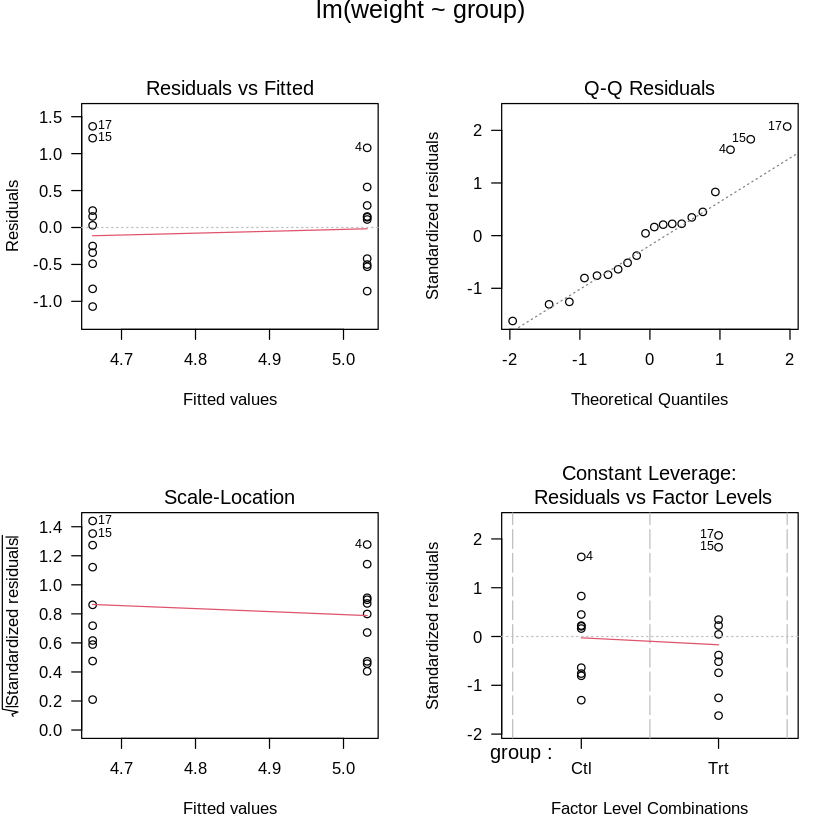

In [ ]:
example(lm)



	demo(persp)
	---- ~~~~~

> ### Demos for  persp()  plots   -- things not in  example(persp)
> ### -------------------------
> 
> require(datasets)

> require(grDevices); require(graphics)

> ## (1) The Obligatory Mathematical surface.
> ##     Rotated sinc function.
> 
> x <- seq(-10, 10, length.out = 50)

> y <- x

> rotsinc <- function(x,y)
+ {
+     sinc <- function(x) { y <- sin(x)/x ; y[is.na(y)] <- 1; y }
+     10 * sinc( sqrt(x^2+y^2) )
+ }

> sinc.exp <- expression(z == Sinc(sqrt(x^2 + y^2)))

> z <- outer(x, y, rotsinc)

> oldpar <- par(bg = "white")

> persp(x, y, z, theta = 30, phi = 30, expand = 0.5, col = "lightblue")

> title(sub=".")## work around persp+plotmath bug

> title(main = sinc.exp)

> persp(x, y, z, theta = 30, phi = 30, expand = 0.5, col = "lightblue",
+       ltheta = 120, shade = 0.75, ticktype = "detailed",
+       xlab = "X", ylab = "Y", zlab = "Z")


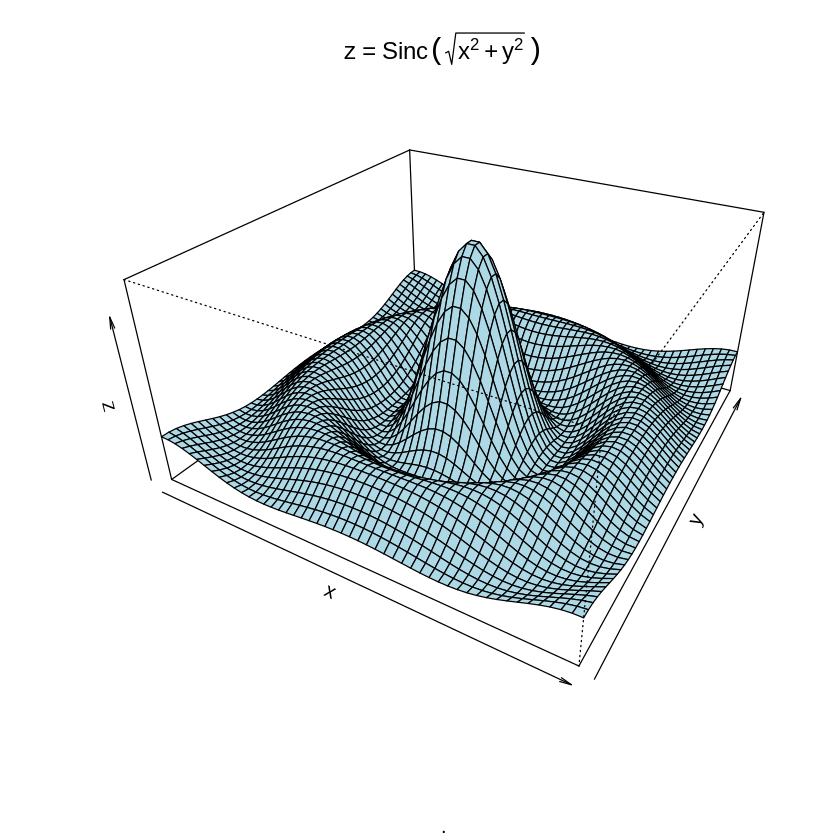


> title(sub=".")## work around persp+plotmath bug

> title(main = sinc.exp)

> ## (2) Visualizing a simple DEM model
> 
> z <- 2 * volcano        # Exaggerate the relief

> x <- 10 * (1:nrow(z))   # 10 meter spacing (S to N)

> y <- 10 * (1:ncol(z))   # 10 meter spacing (E to W)

> persp(x, y, z, theta = 120, phi = 15, scale = FALSE, axes = FALSE)


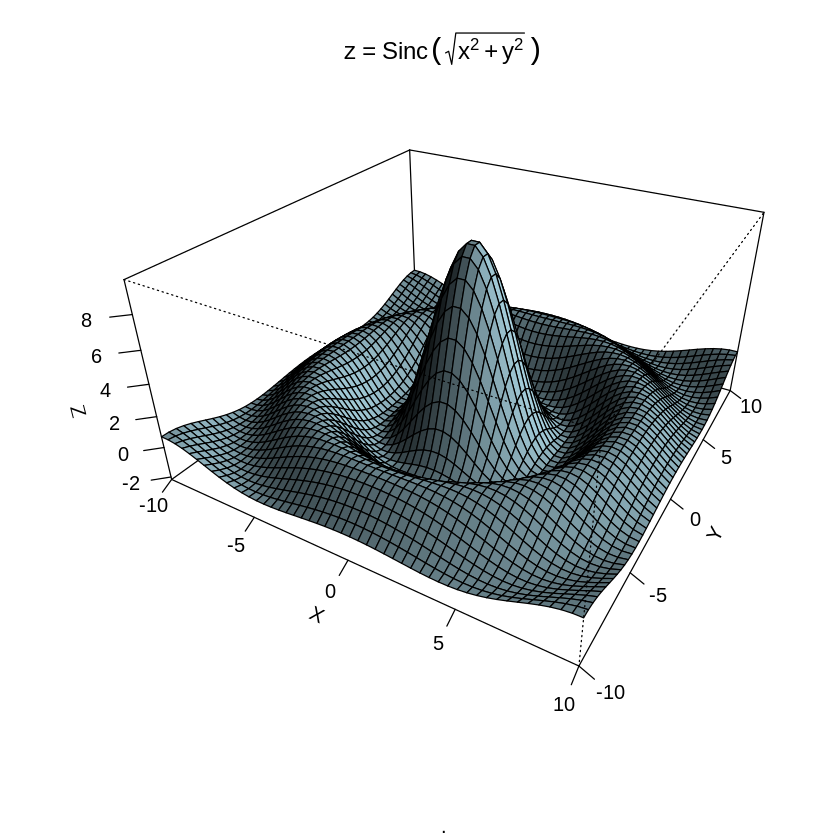


> ## (3) Now something more complex
> ##     We border the surface, to make it more "slice like"
> ##     and color the top and sides of the surface differently.
> 
> z0 <- min(z) - 20

> z <- rbind(z0, cbind(z0, z, z0), z0)

> x <- c(min(x) - 1e-10, x, max(x) + 1e-10)

> y <- c(min(y) - 1e-10, y, max(y) + 1e-10)

> fill <- matrix("green3", nrow = nrow(z)-1, ncol = ncol(z)-1)

> fill[ , i2 <- c(1,ncol(fill))] <- "gray"

> fill[i1 <- c(1,nrow(fill)) , ] <- "gray"

> par(bg = "lightblue")

> persp(x, y, z, theta = 120, phi = 15, col = fill, scale = FALSE, axes = FALSE)


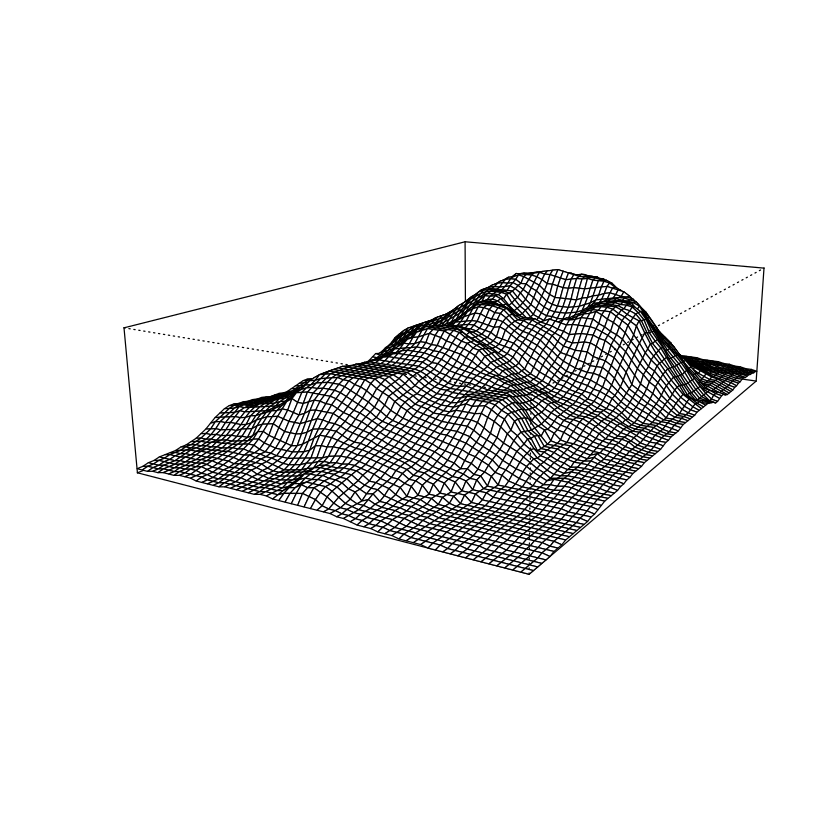


> title(main = "Maunga Whau\nOne of 50 Volcanoes in the Auckland Region.",
+       font.main = 4)

> par(bg = "slategray")

> persp(x, y, z, theta = 135, phi = 30, col = fill, scale = FALSE,
+       ltheta = -120, lphi = 15, shade = 0.65, axes = FALSE)


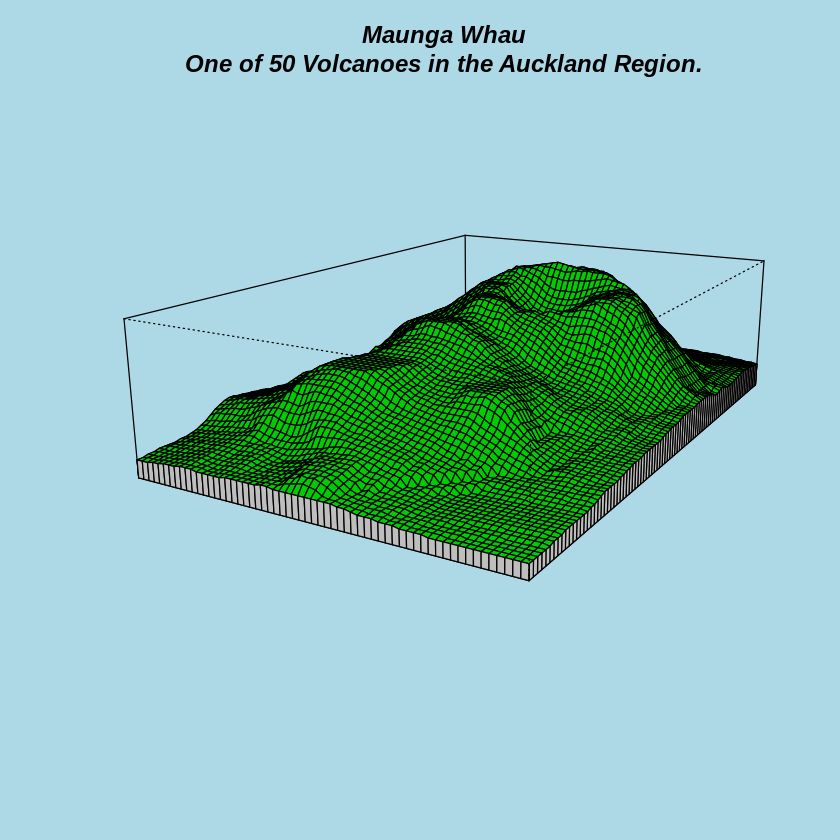


> ## Don't draw the grid lines :  border = NA
> persp(x, y, z, theta = 135, phi = 30, col = "green3", scale = FALSE,
+       ltheta = -120, shade = 0.75, border = NA, box = FALSE)


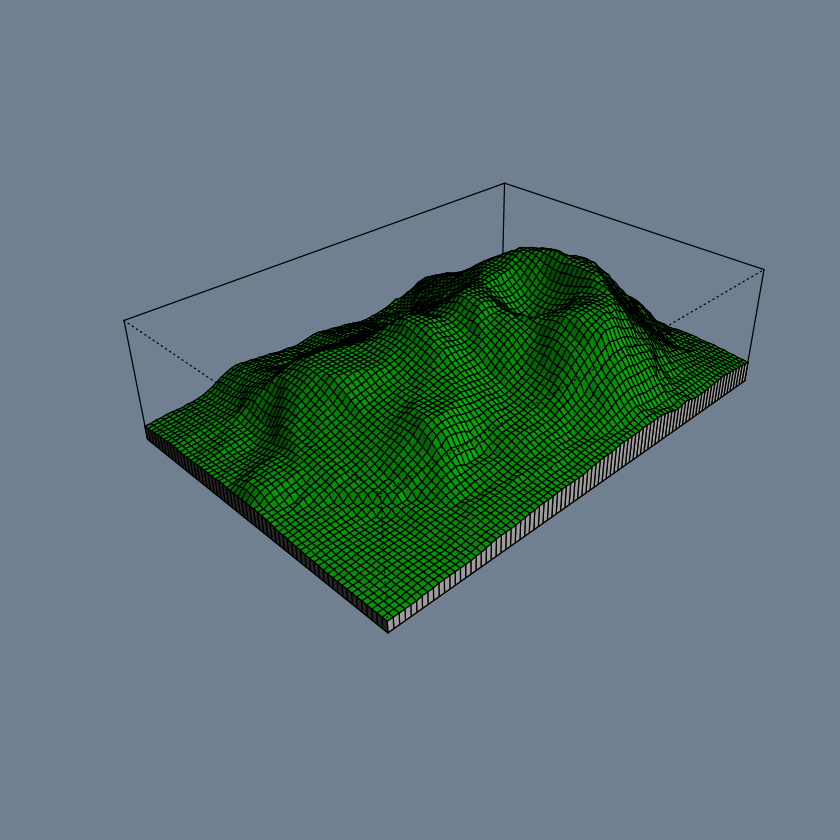


> ## `color gradient in the soil' :
> fcol <- fill ; fcol[] <- terrain.colors(nrow(fcol))

> persp(x, y, z, theta = 135, phi = 30, col = fcol, scale = FALSE,
+       ltheta = -120, shade = 0.3, border = NA, box = FALSE)


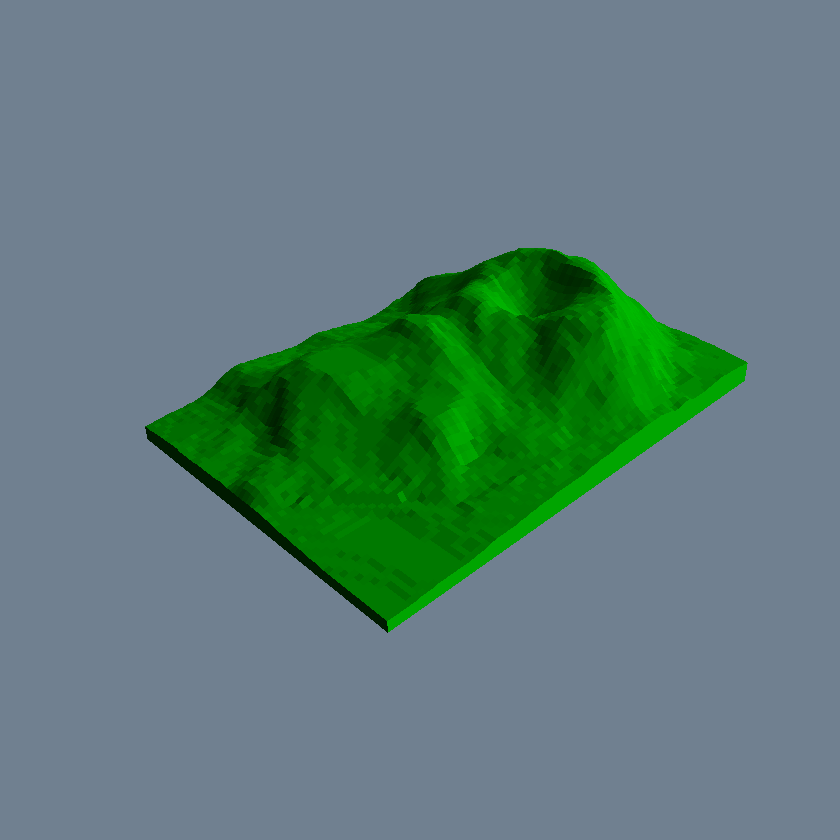


> ## `image like' colors on top :
> fcol <- fill

> zi <- volcano[ -1,-1] + volcano[ -1,-61] +
+            volcano[-87,-1] + volcano[-87,-61]  ## / 4

> fcol[-i1,-i2] <-
+     terrain.colors(20)[cut(zi,
+                            stats::quantile(zi, seq(0,1, length.out = 21)),
+                            include.lowest = TRUE)]

> persp(x, y, 2*z, theta = 110, phi = 40, col = fcol, scale = FALSE,
+       ltheta = -120, shade = 0.4, border = NA, box = FALSE)


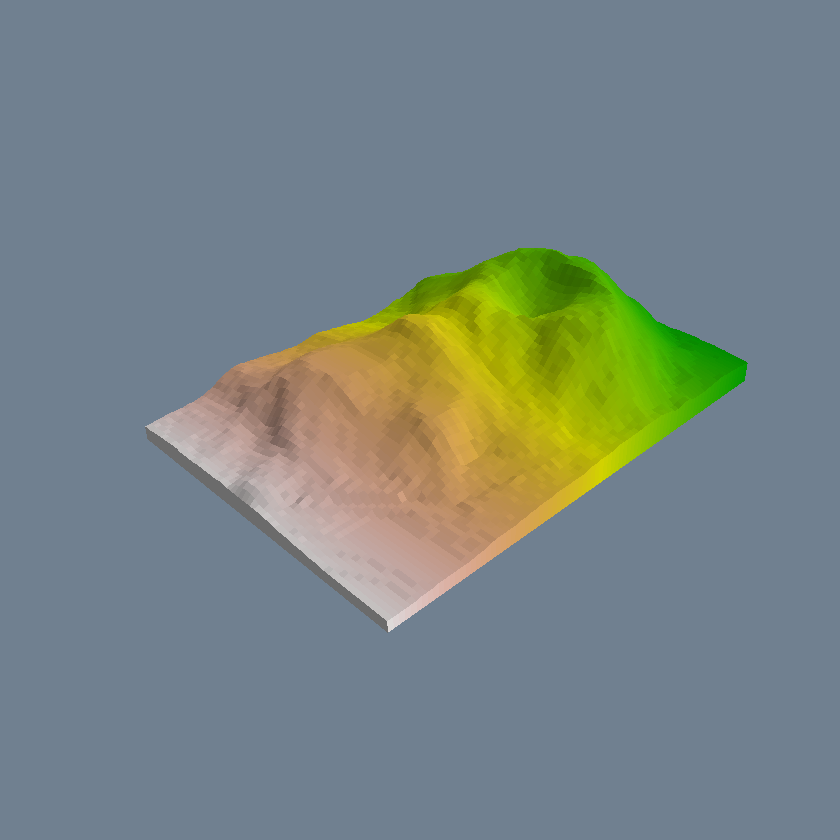


> ## reset par():
> par(oldpar)


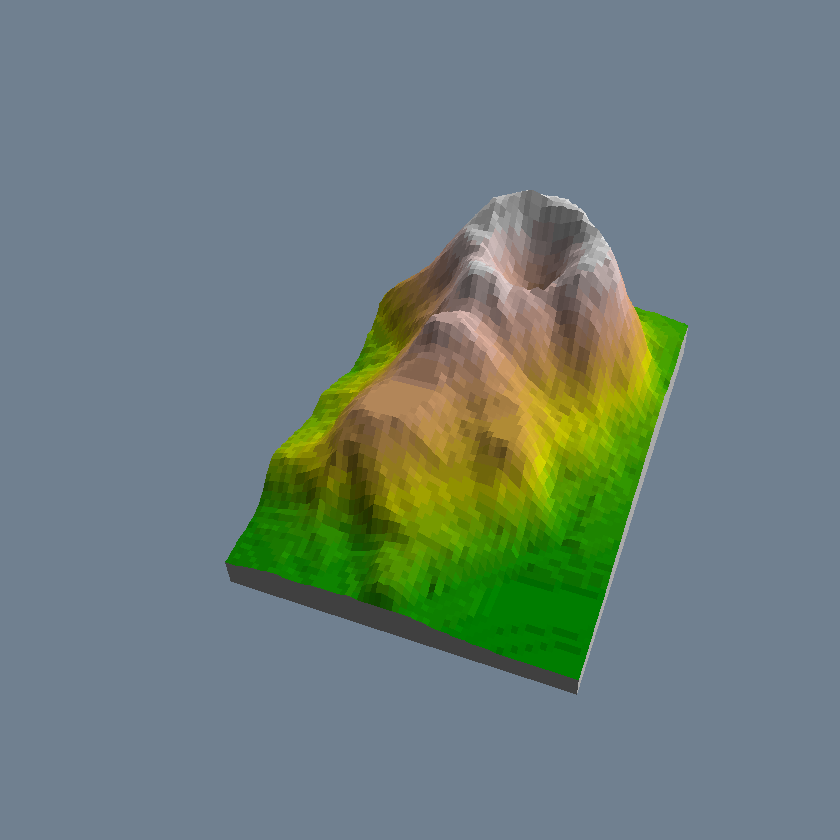

In [ ]:
demo(persp)



	demo(graphics)
	---- ~~~~~~~~

> #  Copyright (C) 1997-2009 The R Core Team
> 
> require(datasets)

> require(grDevices); require(graphics)

> ## Here is some code which illustrates some of the differences between
> ## R and S graphics capabilities.  Note that colors are generally specified
> ## by a character string name (taken from the X11 rgb.txt file) and that line
> ## textures are given similarly.  The parameter "bg" sets the background
> ## parameter for the plot and there is also an "fg" parameter which sets
> ## the foreground color.
> 
> 
> x <- stats::rnorm(50)

> opar <- par(bg = "white")

> plot(x, ann = FALSE, type = "n")

> abline(h = 0, col = gray(.90))

> lines(x, col = "green4", lty = "dotted")

> points(x, bg = "limegreen", pch = 21)

> title(main = "Simple Use of Color In a Plot",
+       xlab = "Just a Whisper of a Label",
+       col.main = "blue", col.lab = gray(.8),
+       cex.main = 1.2, cex.lab = 1.0, font.main = 4, font.lab = 3)

> ## A little color wheel

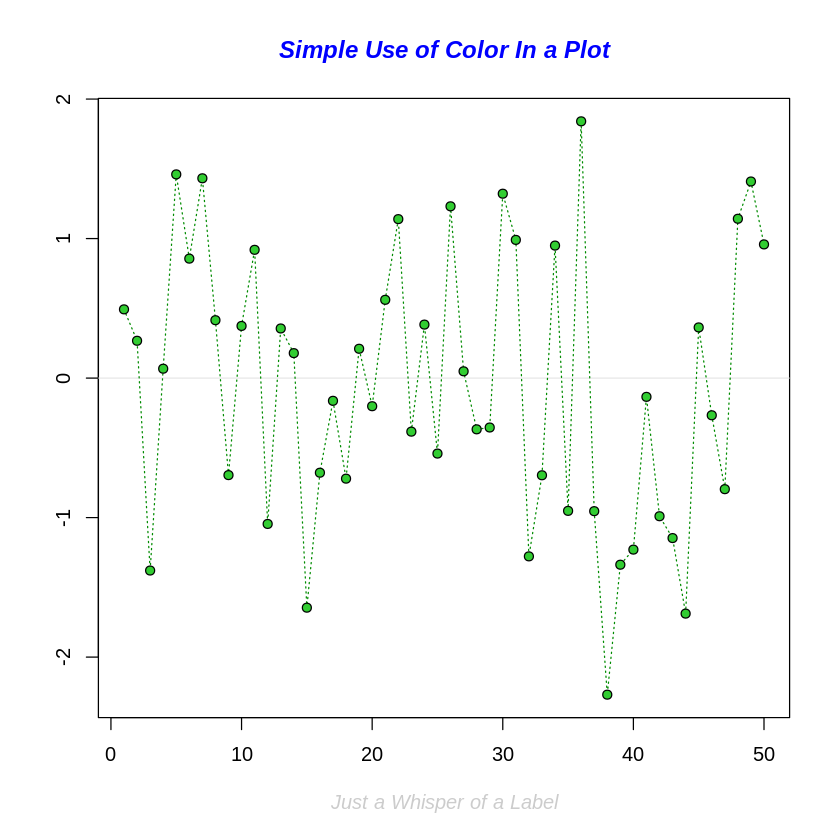


> title(main = "A Sample Color Wheel", cex.main = 1.4, font.main = 3)

> title(xlab = "(Use this as a test of monitor linearity)",
+       cex.lab = 0.8, font.lab = 3)

> ## We have already confessed to having these.  This is just showing off X11
> ## color names (and the example (from the postscript manual) is pretty "cute".
> 
> pie.sales <- c(0.12, 0.3, 0.26, 0.16, 0.04, 0.12)

> names(pie.sales) <- c("Blueberry", "Cherry",
+ 		      "Apple", "Boston Cream", "Other", "Vanilla Cream")

> pie(pie.sales,
+     col = c("purple","violetred1","green3","cornsilk","cyan","white"))


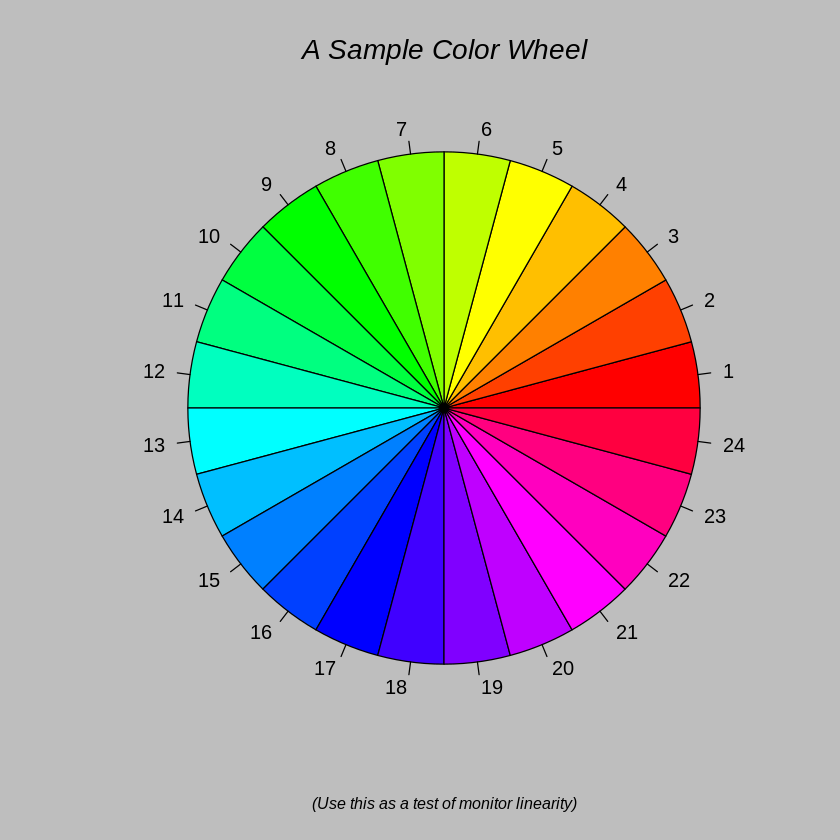


> title(main = "January Pie Sales", cex.main = 1.8, font.main = 1)

> title(xlab = "(Don't try this at home kids)", cex.lab = 0.8, font.lab = 3)

> ## Boxplots:  I couldn't resist the capability for filling the "box".
> ## The use of color seems like a useful addition, it focuses attention
> ## on the central bulk of the data.
> 
> par(bg="cornsilk")

> n <- 10

> g <- gl(n, 100, n*100)

> x <- rnorm(n*100) + sqrt(as.numeric(g))

> boxplot(split(x,g), col="lavender", notch=TRUE)


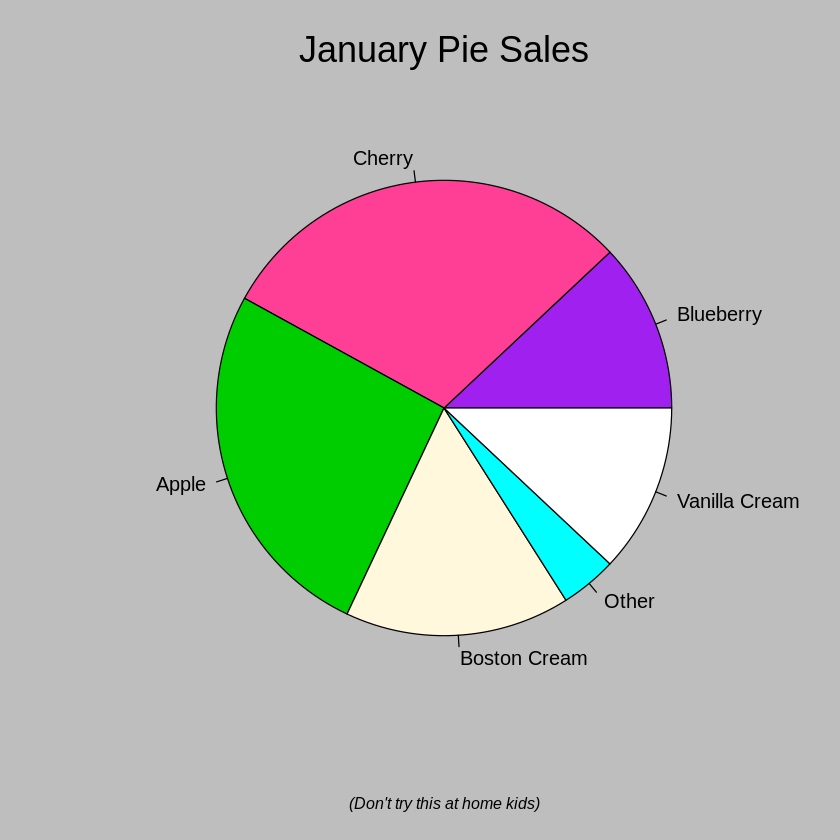


> title(main="Notched Boxplots", xlab="Group", font.main=4, font.lab=1)

> ## An example showing how to fill between curves.
> 
> par(bg="white")

> n <- 100

> x <- c(0,cumsum(rnorm(n)))

> y <- c(0,cumsum(rnorm(n)))

> xx <- c(0:n, n:0)

> yy <- c(x, rev(y))

> plot(xx, yy, type="n", xlab="Time", ylab="Distance")


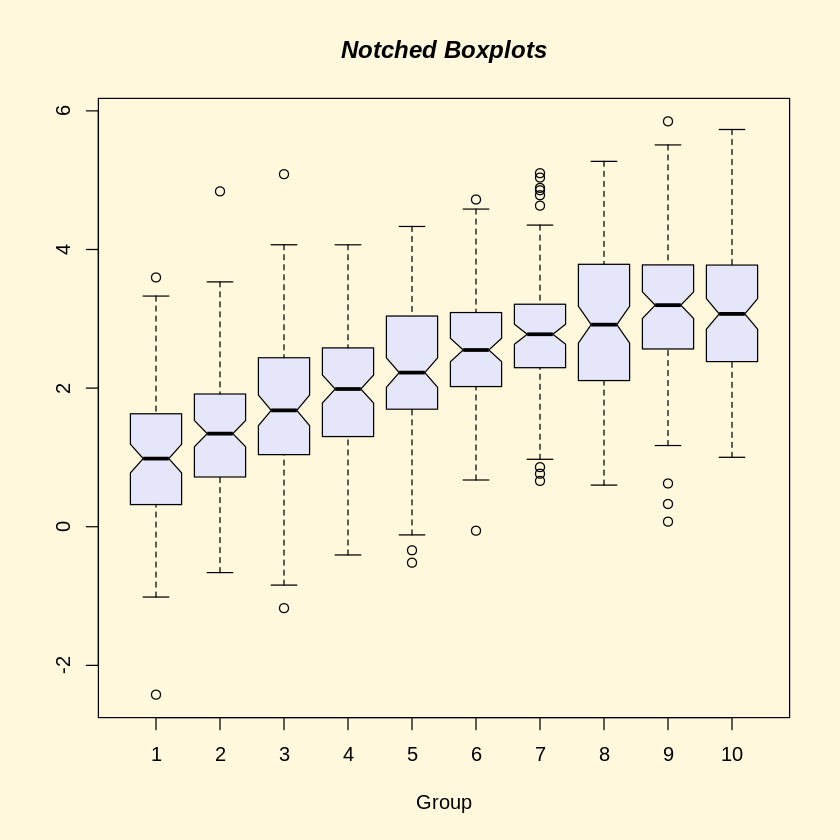


> polygon(xx, yy, col="gray")

> title("Distance Between Brownian Motions")

> ## Colored plot margins, axis labels and titles.	 You do need to be
> ## careful with these kinds of effects.	It's easy to go completely
> ## over the top and you can end up with your lunch all over the keyboard.
> ## On the other hand, my market research clients love it.
> 
> x <- c(0.00, 0.40, 0.86, 0.85, 0.69, 0.48, 0.54, 1.09, 1.11, 1.73, 2.05, 2.02)

> par(bg="lightgray")

> plot(x, type="n", axes=FALSE, ann=FALSE)


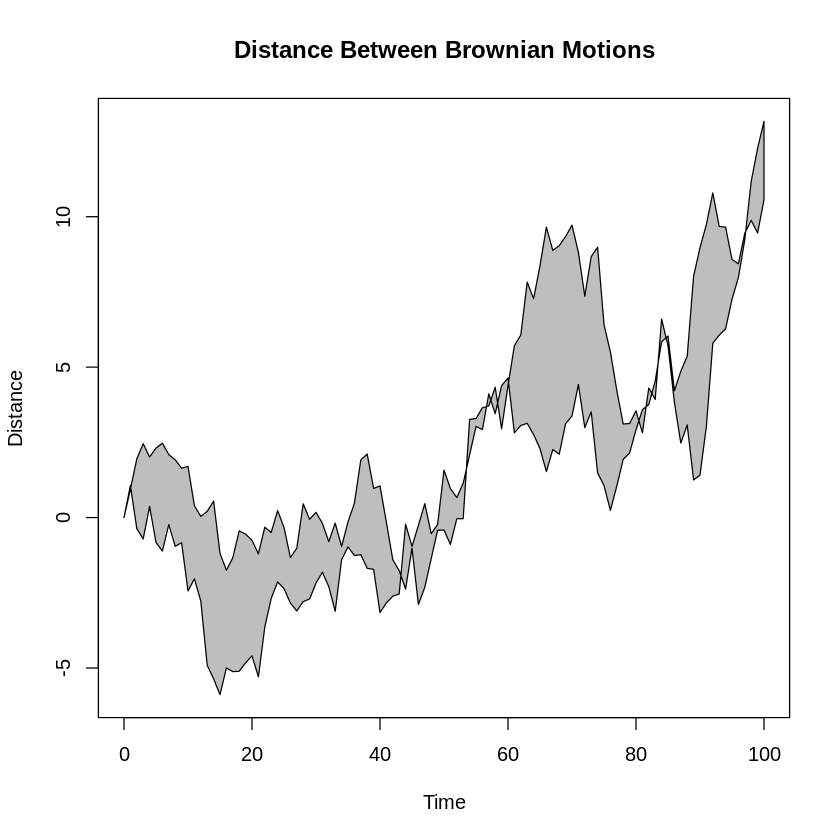


> usr <- par("usr")

> rect(usr[1], usr[3], usr[2], usr[4], col="cornsilk", border="black")

> lines(x, col="blue")

> points(x, pch=21, bg="lightcyan", cex=1.25)

> axis(2, col.axis="blue", las=1)

> axis(1, at=1:12, lab=month.abb, col.axis="blue")

> box()

> title(main= "The Level of Interest in R", font.main=4, col.main="red")

> title(xlab= "1996", col.lab="red")

> ## A filled histogram, showing how to change the font used for the
> ## main title without changing the other annotation.
> 
> par(bg="cornsilk")

> x <- rnorm(1000)

> hist(x, xlim=range(-4, 4, x), col="lavender", main="")


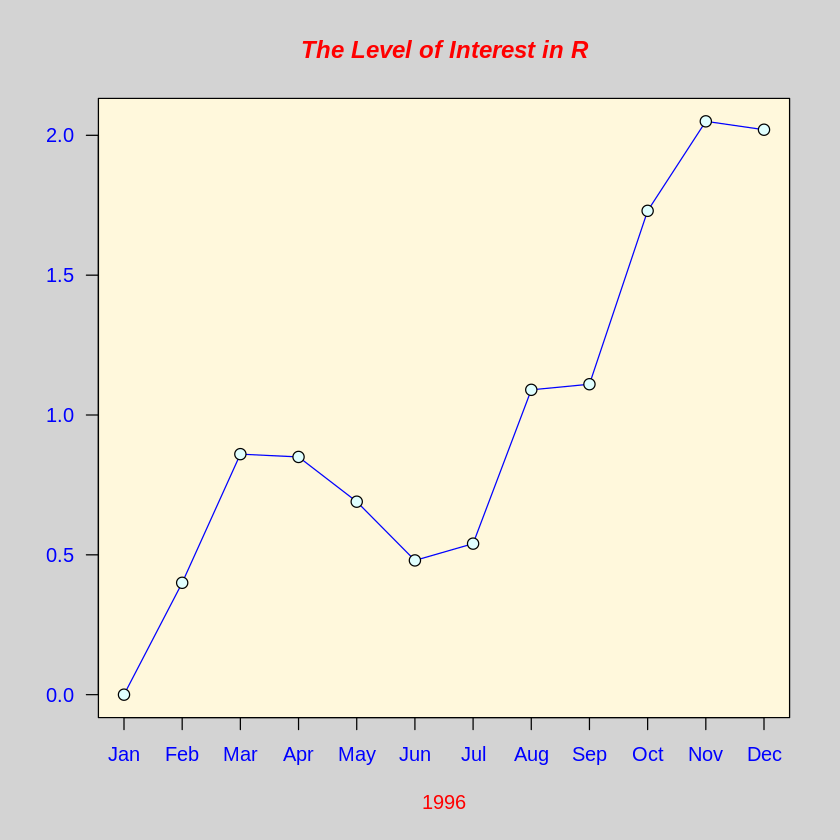


> title(main="1000 Normal Random Variates", font.main=3)

> ## A scatterplot matrix
> ## The good old Iris data (yet again)
> 
> pairs(iris[1:4], main="Edgar Anderson's Iris Data", font.main=4, pch=19)


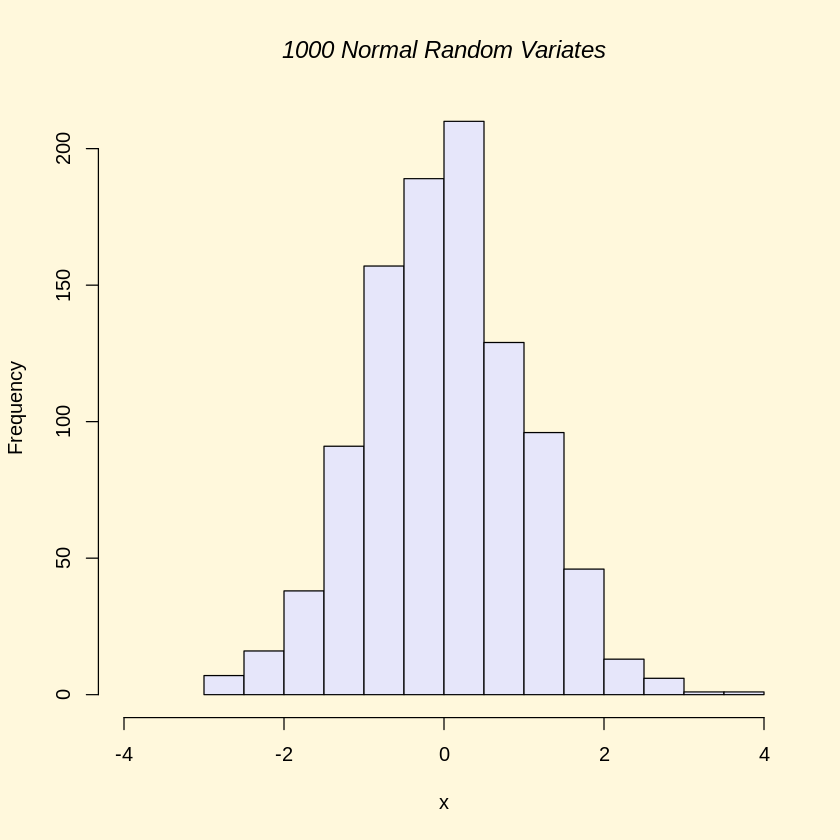


> pairs(iris[1:4], main="Edgar Anderson's Iris Data", pch=21,
+       bg = c("red", "green3", "blue")[unclass(iris$Species)])


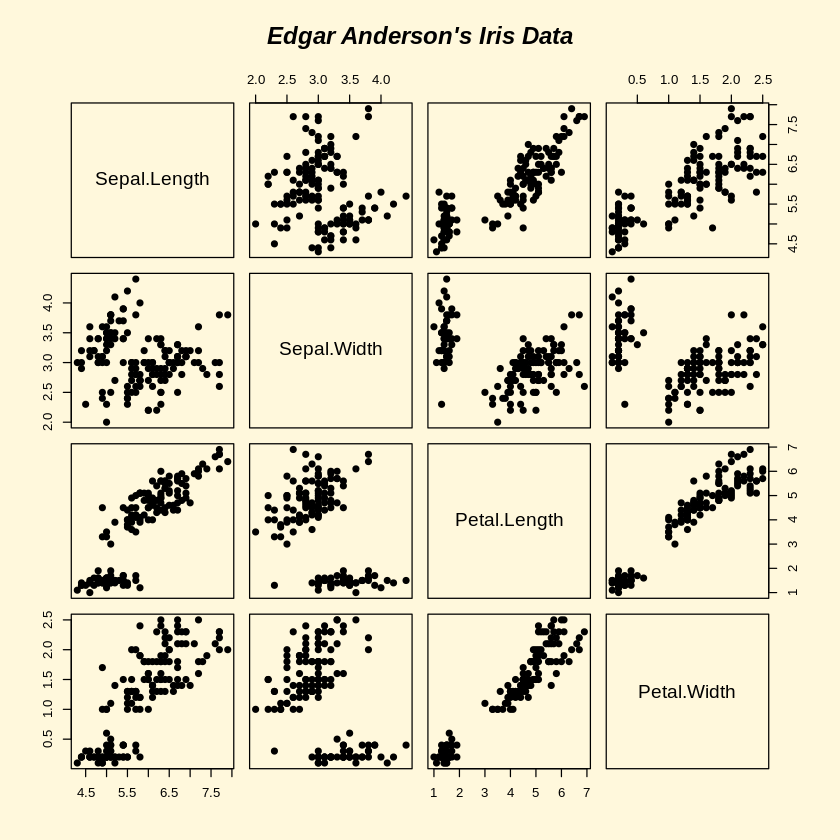


> ## Contour plotting
> ## This produces a topographic map of one of Auckland's many volcanic "peaks".
> 
> x <- 10*1:nrow(volcano)

> y <- 10*1:ncol(volcano)

> lev <- pretty(range(volcano), 10)

> par(bg = "lightcyan")

> pin <- par("pin")

> xdelta <- diff(range(x))

> ydelta <- diff(range(y))

> xscale <- pin[1]/xdelta

> yscale <- pin[2]/ydelta

> scale <- min(xscale, yscale)

> xadd <- 0.5*(pin[1]/scale - xdelta)

> yadd <- 0.5*(pin[2]/scale - ydelta)

> plot(numeric(0), numeric(0),
+      xlim = range(x)+c(-1,1)*xadd, ylim = range(y)+c(-1,1)*yadd,
+      type = "n", ann = FALSE)


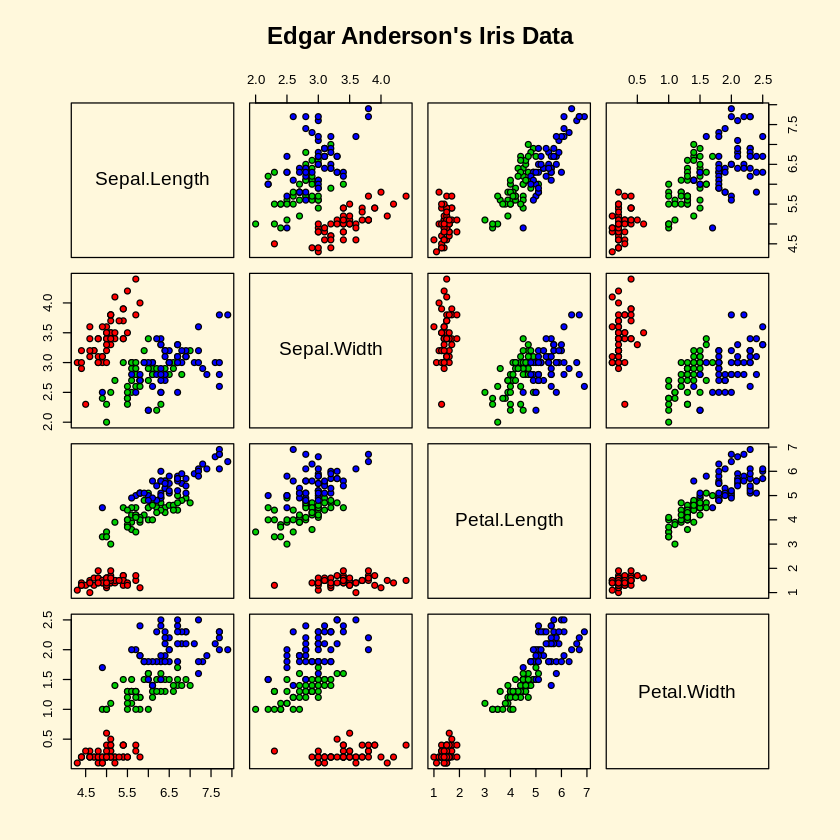


> usr <- par("usr")

> rect(usr[1], usr[3], usr[2], usr[4], col="green3")

> contour(x, y, volcano, levels = lev, col="yellow", lty="solid", add=TRUE)

> box()

> title("A Topographic Map of Maunga Whau", font= 4)

> title(xlab = "Meters North", ylab = "Meters West", font= 3)

> mtext("10 Meter Contour Spacing", side=3, line=0.35, outer=FALSE,
+       at = mean(par("usr")[1:2]), cex=0.7, font=3)

> ## Conditioning plots
> 
> par(bg="cornsilk")

> coplot(lat ~ long | depth, data = quakes, pch = 21, bg = "green3")


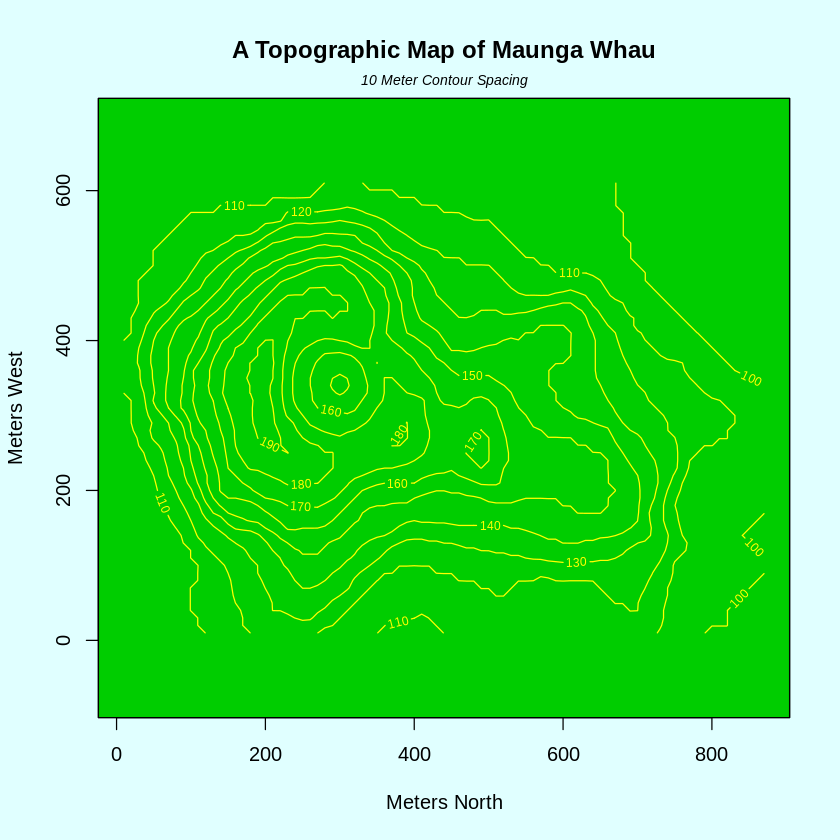


> par(opar)


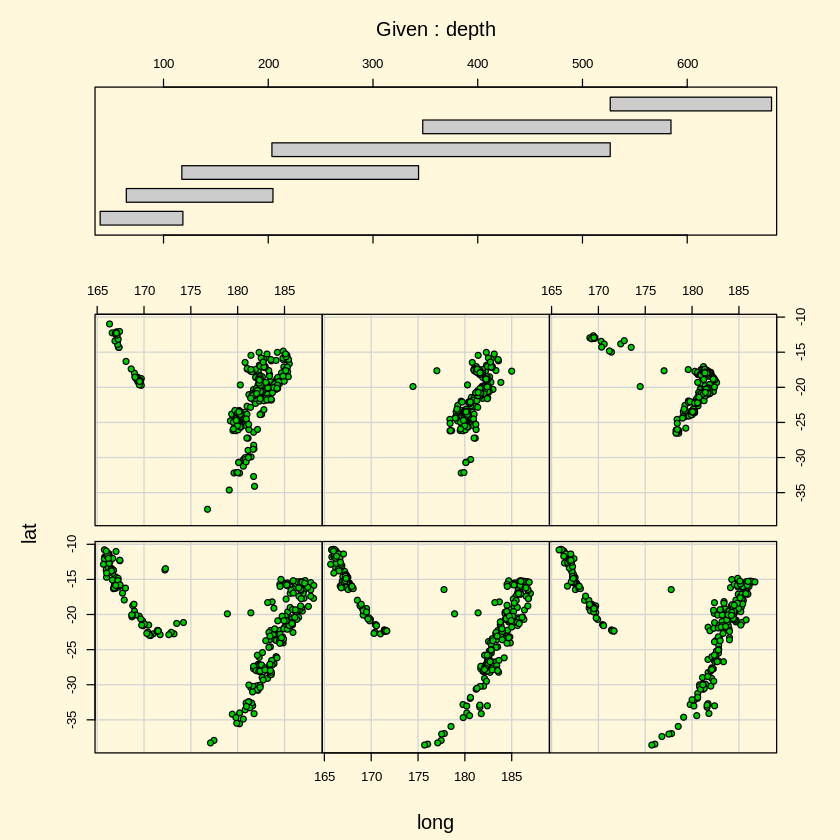

In [ ]:
demo(graphics)

***PACKAGES AND LIBRARIES IN R***

In [ ]:
library

function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE, 
    logical.return = FALSE, warn.conflicts, quietly = FALSE, 
    verbose = getOption("verbose"), mask.ok, exclude, include.only, 
    attach.required = missing(include.only)) 
{
    conf.ctrl <- getOption("conflicts.policy")
    if (is.character(conf.ctrl)) 
        conf.ctrl <- switch(conf.ctrl, strict = list(error = TRUE, 
            warn = FALSE), depends.ok = list(error = TRUE, generics.ok = TRUE, 
            can.mask = c("base", "methods", "utils", "grDevices", 
                "graphics", "stats"), depends.ok = TRUE), warning(gettextf("unknown conflict policy: %s", 
            sQuote(conf.ctrl)), call. = FALSE, domain = NA))
    if (!is.list(conf.ctrl)) 
        conf.ctrl <- NULL
    stopOnConflict <- isTRUE(conf.ctrl$error)
    if (missing(warn.conflicts)) 
        warn.conflicts <- !isFALSE(conf.ctrl$warn)
    if (!missing(include.only) && !missing(exclude)) 
        stop("only one of 'include.only' and 'exclude' can be used", 
            call. = FALSE)
    testRversion <- function(pkgInfo, pkgname, pkgpath) {
        if (is.null(built <- pkgInfo$Built)) 
            stop(gettextf("package %s has not been installed properly\n", 
                sQuote(pkgname)), call. = FALSE, domain = NA)
        R_version_built_under <- as.numeric_version(built$R)
        if (R_version_built_under < "3.0.0") 
            stop(gettextf("package %s was built before R 3.0.0: please re-install it", 
                sQuote(pkgname)), call. = FALSE, domain = NA)
        current <- getRversion()
        if (length(Rdeps <- pkgInfo$Rdepends2)) {
            for (dep in Rdeps) if (length(dep) > 1L) {
                target <- dep$version
                res <- do.call(dep$op, if (is.character(target)) 
                  list(as.numeric(R.version[["svn rev"]]), as.numeric(sub("^r", 
                    "", target)))
                else list(current, as.numeric_version(target)))
                if (!res) 
                  stop(gettextf("This is R %s, package %s needs %s %s", 
                    current, sQuote(pkgname), dep$op, target), 
                    call. = FALSE, domain = NA)
            }
        }
        if (R_version_built_under > current) 
            warning(gettextf("package %s was built under R version %s", 
                sQuote(pkgname), as.character(built$R)), call. = FALSE, 
                domain = NA)
        platform <- built$Platform
        r_arch <- .Platform$r_arch
        if (.Platform$OS.type == "unix") {
        }
        else {
            if (nzchar(platform) && !grepl("mingw", platform)) 
                stop(gettextf("package %s was built for %s", 
                  sQuote(pkgname), platform), call. = FALSE, 
                  domain = NA)
        }
        if (nzchar(r_arch) && file.exists(file.path(pkgpath, 
            "libs")) && !file.exists(file.path(pkgpath, "libs", 
            r_arch))) 
            stop(gettextf("package %s is not installed for 'arch = %s'", 
                sQuote(pkgname), r_arch), call. = FALSE, domain = NA)
    }
    checkNoGenerics <- function(env, pkg) {
        nenv <- env
        ns <- .getNamespace(as.name(pkg))
        if (!is.null(ns)) 
            nenv <- asNamespace(ns)
        if (exists(".noGenerics", envir = nenv, inherits = FALSE)) 
            TRUE
        else {
            !any(startsWith(names(env), ".__T"))
        }
    }
    checkConflicts <- function(package, pkgname, pkgpath, nogenerics, 
        env) {
        dont.mind <- c("last.dump", "last.warning", ".Last.value", 
            ".Random.seed", ".Last.lib", ".onDetach", ".packageName", 
            ".noGenerics", ".required", ".no_S3_generics", ".Depends", 
            ".requireCachedGenerics")
        sp <- search()
        lib.pos <- which(sp == pkgname)
        ob <- names(as.environment(lib.pos))
        if (!nogenerics) {
            these <- ob[startsWith(ob, ".__T__")]
            gen <- gsub(".__T__(.*):([^:]+)", "

In [ ]:
library(spatial)

In [ ]:
packageDescription

function (pkg, lib.loc = NULL, fields = NULL, drop = TRUE, encoding = "") 
{
    retval <- list()
    if (!is.null(fields)) {
        fields <- as.character(fields)
        retval[fields] <- NA
    }
    pkgpath <- if (is.null(lib.loc)) {
        if (pkg == "base") 
            file.path(.Library, "base")
        else if (isNamespaceLoaded(pkg)) 
            getNamespaceInfo(pkg, "path")
        else if ((envname <- paste0("package:", pkg)) %in% search()) {
            attr(as.environment(envname), "path")
        }
    }
    if (is.null(pkgpath)) 
        pkgpath <- ""
    if (pkgpath == "") {
        for (lib in lib.loc %||% .libPaths()) if (file.access(file.path(lib, 
            pkg), 5) == 0L) {
            pkgpath <- file.path(lib, pkg)
            break
        }
    }
    if (pkgpath == "") {
        warning(gettextf("no package '%s' was found", pkg), domain = NA)
        return(NA)
    }
    if (file.exists(file <- file.path(pkgpath, "Meta", "package.rds"))) {
        desc <- readRDS(file)$DESCRIPTION
        if (length(desc) < 1) 
            stop(gettextf("metadata of package '%s' is corrupt", 
                pkg), domain = NA)
        desc <- as.list(desc)
    }
    else if (file.exists(file <- file.path(pkgpath, "DESCRIPTION"))) {
        dcf <- read.dcf(file = file, keep.white = tools:::.keep_white_description_fields)
        if (NROW(dcf) < 1L) 
            stop(gettextf("DESCRIPTION file of package '%s' is corrupt", 
                pkg), domain = NA)
        desc <- as.list(dcf[1, ])
    }
    else file <- ""
    if (nzchar(file)) {
        if (is.null(pkgname <- desc[["Package"]]) || (pkgname != 
            pkg)) {
            warning(gettextf("no package '%s' was found", pkg), 
                domain = NA)
            return(NA)
        }
        enc <- desc[["Encoding"]]
        if (!is.null(enc) && !is.na(encoding)) {
            if (missing(encoding) && Sys.getlocale("LC_CTYPE") == 
                "C") 
                encoding <- "ASCII//TRANSLIT"
            if (encoding != enc) {
                newdesc <- try(lapply(desc, iconv, from = enc, 
                  to = encoding))
                dOk <- function(nd) !inherits(nd, "try-error") && 
                  !anyNA(nd)
                ok <- dOk(newdesc)
                if (!ok && !endsWith(encoding, "//TRANSLIT")) 
                  ok <- dOk(newdesc <- try(lapply(desc, iconv, 
                    from = enc, to = paste0(encoding, "//TRANSLIT"))))
                if (!ok) 
                  ok <- dOk(newdesc <- try(lapply(desc, iconv, 
                    from = enc, to = "ASCII//TRANSLIT", sub = "?")))
                if (ok) 
                  desc <- newdesc
                else warning("'DESCRIPTION' file has an 'Encoding' field and re-encoding is not possible", 
                  call. = FALSE)
            }
        }
        if (!is.null(fields)) {
            ok <- names(desc) %in% fields
            retval[names(desc)[ok]] <- desc[ok]
        }
        else retval[names(desc)] <- desc
    }
    if ((file == "") || (length(retval) == 0)) {
        warning(gettextf("DESCRIPTION file of package '%s' is missing or broken", 
            pkg), domain = NA)
        return(NA)
    }
    if (drop && length(fields) == 1L) 
        return(retval[[1L]])
    class(retval) <- "packageDescription"
    if (!is.null(fields)) 
        attr(retval, "fields") <- fields
    attr(retval, "file") <- file
    retval
}
<bytecode: 0x5d4612ad7190>
<environment: namespace:utils>

In [ ]:
library(help=spatial)

***INSTALLING PACKAGES AND LIBRARIES IN R***

In [ ]:
install.packages

function (pkgs, lib, repos = getOption("repos"), contriburl = contrib.url(repos, 
    type), method, available = NULL, destdir = NULL, dependencies = NA, 
    type = getOption("pkgType"), configure.args = getOption("configure.args"), 
    configure.vars = getOption("configure.vars"), clean = FALSE, 
    Ncpus = getOption("Ncpus", 1L), verbose = getOption("verbose"), 
    libs_only = FALSE, INSTALL_opts, quiet = FALSE, keep_outputs = FALSE, 
    ...) 
{
    if (!(is.character(type) && length(type) == 1L)) 
        stop(gettextf("'%s' must be a character string", "type"), 
            domain = NA)
    type2 <- .Platform$pkgType
    if (type == "binary") {
        if (type2 == "source") 
            stop("type 'binary' is not supported on this platform")
        else type <- type2
        if (type == "both" && (!missing(contriburl) || !is.null(available))) 
            stop("specifying 'contriburl' or 'available' requires a single type, not type = \"both\"")
    }
    if (is.logical(clean) && clean) 
        clean <- "--clean"
    if (is.logical(dependencies) && is.na(dependencies)) 
        dependencies <- if (!missing(lib) && length(lib) > 1L) 
            FALSE
        else c("Depends", "Imports", "LinkingTo")
    get_package_name <- function(pkg) {
        gsub("_[.](zip|tar[.](gz|bzip2|bz2|xz|zstd|zst))", "", 
            gsub(.standard_regexps()$valid_package_version, "", 
                basename(pkg)))
    }
    getConfigureArgs <- function(pkg) {
        if (.Platform$OS.type == "windows") 
            return(character())
        if (length(pkgs) == 1L && length(configure.args) && length(names(configure.args)) == 
            0L) 
            return(paste0("--configure-args=", shQuote(paste(configure.args, 
                collapse = " "))))
        pkg <- get_package_name(pkg)
        if (length(configure.args) && length(names(configure.args)) && 
            pkg %in% names(configure.args)) 
            config <- paste0("--configure-args=", shQuote(paste(configure.args[[pkg]], 
                collapse = " ")))
        else config <- character()
        config
    }
    getConfigureVars <- function(pkg) {
        if (.Platform$OS.type == "windows") 
            return(character())
        if (length(pkgs) == 1L && length(configure.vars) && length(names(configure.vars)) == 
            0L) 
            return(paste0("--configure-vars=", shQuote(paste(configure.vars, 
                collapse = " "))))
        pkg <- get_package_name(pkg)
        if (length(configure.vars) && length(names(configure.vars)) && 
            pkg %in% names(configure.vars)) 
            config <- paste0("--configure-vars=", shQuote(paste(configure.vars[[pkg]], 
                collapse = " ")))
        else config <- character()
        config
    }
    get_install_opts <- function(pkg) {
        if (!length(INSTALL_opts)) 
            character()
        else paste(INSTALL_opts[[get_package_name(pkg)]], collapse = " ")
    }
    if (missing(pkgs)) {
        if (!interactive()) 
            stop("no packages were specified")
        if (.Platform$OS.type == "windows" || .Platform$GUI == 
            "AQUA" || (capabilities("tcltk") && capabilities("X11") && 
            suppressWarnings(tcltk::.TkUp))) {
        }
        else stop("no packages were specified")
        if (is.null(available)) {
            av <- available.packages(contriburl = contriburl, 
                method = method, ...)
            if (missing(repos)) 
                repos <- getOption("repos")
            if (type != "both") 
                available <- av
        }
        else av <- available
        if (NROW(av)) {
            pkgs <- select.list(sort(unique(rownames(av))), multiple = TRUE, 
                title = "Packages", graphics = TRUE)
        }
    }
    if (.Platform$OS.type == "windows" && length(pkgs)) {
        pkgnames <- get_package_name(pkgs)
        inuse <- search()
        inuse <- sub("^package:", "", inuse[grep("^package:", 
            inuse)

In [ ]:
install.packages("boot")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
install.packages("cluster")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
install.packages("boot")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



***UNINSTALLING PACKAGES INSTALLED ON MY COMPUTER***

In [ ]:
installed.packages()[, "Package"] #to check which packages are installed

boot         cluster       IRdisplay        IRkernel          pbdZMQ 
         "boot"       "cluster"     "IRdisplay"      "IRkernel"        "pbdZMQ" 
           repr         askpass       backports       base64enc             bit 
         "repr"       "askpass"     "backports"     "base64enc"           "bit" 
          bit64            blob            boot            brew            brio 
        "bit64"          "blob"          "boot"          "brew"          "brio" 
          broom           bslib          cachem           callr      cellranger 
        "broom"         "bslib"        "cachem"         "callr"    "cellranger" 
          class             cli           clipr         cluster       codetools 
        "class"           "cli"         "clipr"       "cluster"     "codetools" 
     commonmark      conflicted           cpp11          crayon     credentials 
   "commonmark"    "conflicted"         "cpp11"        "crayon"   "credentials" 
           curl      data.table             DBI          dbplyr            desc 
         "curl"    "data.table"           "DBI"        "dbplyr"          "desc" 
       devtools         diffobj          digest         downlit           dplyr 
     "devtools"       "diffobj"        "digest"       "downlit"         "dplyr" 
         dtplyr        ellipsis        evaluate           fansi          farver 
       "dtplyr"      "ellipsis"      "evaluate"         "fansi"        "farver" 
        fastmap     fontawesome         forcats              fs          gargle 
      "fastmap"   "fontawesome"       "forcats"            "fs"        "gargle" 
       generics            gert         ggplot2              gh        gitcreds 
     "generics"          "gert"       "ggplot2"            "gh"      "gitcreds" 
           glue     googledrive   googlesheets4          gtable           haven 
         "glue"   "googledrive" "googlesheets4"        "gtable"         "haven" 
          highr             hms       htmltools     htmlwidgets          httpuv 
        "highr"           "hms"     "htmltools"   "htmlwidgets"        "httpuv" 
           httr           httr2             ids             ini         isoband 
         "httr"         "httr2"           "ids"           "ini"       "isoband" 
      jquerylib        jsonlite      KernSmooth           knitr        labeling 
    "jquerylib"      "jsonlite"    "KernSmooth"         "knitr"      "labeling" 
          later         lattice       lifecycle       lubridate        magrittr 
        "later"       "lattice"     "lifecycle"     "lubridate"      "magrittr" 
           MASS          Matrix         memoise            mgcv            mime 
         "MASS"        "Matrix"       "memoise"          "mgcv"          "mime" 
         miniUI          modelr            nnet         openssl            otel 
       "miniUI"        "modelr"          "nnet"       "openssl"          "otel" 
            pak          pillar        pkgbuild       pkgconfig         pkgdown 
          "pak"        "pillar"      "pkgbuild"     "pkgconfig"       "pkgdown" 
        pkgload          praise     prettyunits        processx         profvis 
      "pkgload"        "praise"   "prettyunits"      "processx"       "profvis" 
       progress        promises              ps           purrr              R6 
     "progress"      "promises"            "ps"         "purrr"            "R6" 
           ragg        rappdirs       rcmdcheck    RColorBrewer            Rcpp 
         "ragg"      "rappdirs"     "rcmdcheck"  "RColorBrewer"          "Rcpp" 
          readr          readxl         rematch        rematch2          reprex 
        "readr"        "readxl"       "rematch"      "rematch2"        "reprex" 
          rlang       rmarkdown        roxygen2           rpart       rprojroot 
        "rlang"     "rmarkdown"      "roxygen2"         "rpart"     "rprojroot" 
     rstudioapi       rversions           rvest              S7            sass 
   "rstudioapi"     "rversions"         "r

In [ ]:
find("lowess")

[1] "package:stats"

***--THANKYOU--***